# Debugging the EOD assignment, 2-fish ground truth

Recording `2024-02-13T14_33_21`: fish 1 emits, fish 0 is silent, so every EOD given to fish 0 is an error. The EODs are the 3,532 in
frames good by both the mask QC and the SLEAP list, with the model voltages cached by `EOD_assignment_ground_truth.ipynb`
(no field solves here). Main rule: shape only, e = 0 (96.0% correct, 141 misses).

| step | what could go wrong | test |
|---|---|---|
| 1. recording → peak pattern r | low amplitude / noise, overlapping EODs, wrong sample | miss rate vs amplitude, SNR, one-waveform fraction; other choices of the pattern |
| 2. electrodes | wrong wiring, flipped polarity, unequal gains | recorded vs model voltage, pair by pair, with fish 1 as emitter |
| 3. video ↔ EOD sync | EOD matched to the wrong frame | accuracy with shifted frames |
| 4. masks → midline, head | head and tail swapped | area-rule head vs SLEAP head |
| 5. field model | pattern wrong even for the right fish | residual vs position; model parameters |
| 6. comparison | the two fish look alike at the electrodes | model similarity vs miss rate |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eod_assign import (load_electrode_pairs, eod_sample_count, recorded_pair_traces_all, rank1_pattern, eod_phase_samples,
                        compare_patterns)

EOD_CSV = 'data/2_fish_silent/Data_1fish_2024-02-13T14_33_21.csv'
ELECTRODES_CSV = 'data/electrodes_signed_px_coord_2024-02-13.csv'
OUT = 'results/eod_ground_truth'
P = 912                                          # video frame size (px)
FS = 50000.0                                     # electrode sampling rate (Hz)
FISH, EMITTER = (0, 1), 1
G0 = 0.505                                       # calibrated gain (model units -> recorded units), from the main notebook
FISH_COLOR = {0: '#2E8B57', 1: '#D45087'}

df_eod = pd.read_csv(EOD_CSV)
n_samp = eod_sample_count(df_eod)
pairs = load_electrode_pairs(ELECTRODES_CSV, P)
pair_ids = [pid for pid, _, _ in pairs]
FLIPPED = (2, 5)                                 # pairs whose polarity was flipped in the electrode files (restored since)
pairs_orig = pairs                               # original polarity, as in the assignment run
pairs_flipped = [(pid, pm, pp) if pid in FLIPPED else (pid, pp, pm) for pid, pp, pm in pairs]   # pairs 2 and 5 swapped
rules = pd.read_csv(f'{OUT}/eod_assignments_my_pipeline.csv', index_col='row')
res = pd.read_pickle(f'{OUT}/model_voltages_N150_sink0_el46ee63.pkl').loc[rules.index]   # assignment run: sink on the tail tip,
                                                                                         # original polarity of pairs 2 and 5
R, U = np.stack(res.v_rec), np.stack(res.u)       # recorded peak pattern (n, pairs), unit-current model (n, fish, pairs)
V = recorded_pair_traces_all(df_eod.loc[res.index], pair_ids, n_samp)   # recorded windows (n, pairs, samples)
miss = (rules['fish | shape only'] != EMITTER).to_numpy()
n = len(res)
print(f"{n} EODs, {miss.sum()} misses ({miss.mean():.1%}) with the shape-only rule")

def shape_correct(Rx):
    '''% of EODs given to the emitter by the shape-only rule when the recorded pattern is Rx (n, pairs).'''
    D = np.array([[compare_patterns(m, r)[0] for m in Ms] for Ms, r in zip(U, Rx)])
    return 100 * (D.argmin(1) == EMITTER).mean()

def miss_rate_by(x, q=10):
    '''% misses in each decile of x, with the decile centres.'''
    b = pd.qcut(x, q, duplicates='drop')
    s = pd.Series(miss).groupby(b, observed=True).mean() * 100
    return np.array([i.mid for i in s.index]), s.to_numpy()

3532 EODs, 141 misses (4.0%) with the shape-only rule


## Step 1. The recorded pattern

The assignment uses one number per pair: the recorded voltage at the single sample where |V| peaks over all pairs (`peak_pattern`).
Checks:
- **amplitude** |r| and **signal-to-noise** (peak / RMS of the 6 quietest samples of the window, which lie outside the EOD);
- **one-waveform fraction**: share of the window's variance in its best rank-1 fit. In the resistive model every pair sees the same
  waveform, so a clean single EOD is close to 1; overlapping EODs or noise lower it;
- **peak sample** position in the window;
- **other ways to take the pattern**: first phase, second phase, or the rank-1 spatial pattern of the whole window.

,|r|,SNR,one-waveform fraction,peak sample
correct,0.266,168.687,0.999,12.0
miss,0.156,148.207,0.997,12.0


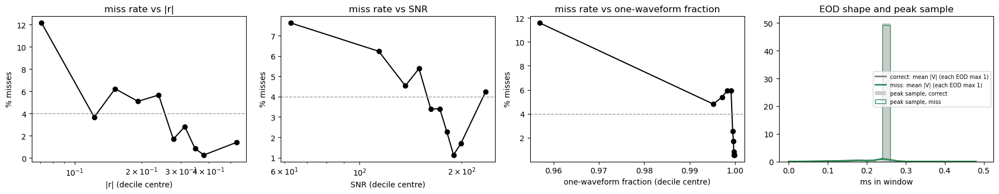

,% correct (shape only)
peak sample (current),96.01
first phase,95.78
second phase,96.01
rank-1 pattern of the window,95.92


In [2]:
t_ms = np.arange(n_samp) / FS * 1e3
ts = np.abs(V).max(axis=1).argmax(axis=1)                          # peak sample of each EOD
assert np.allclose(V[np.arange(n), :, ts], R)                      # = the cached pattern
amp = np.linalg.norm(R, axis=1)
quiet = np.argsort(np.abs(V).mean(axis=(0, 1)))[:6]                # samples outside the EOD (all EODs)
noise = np.sqrt((V[:, :, quiet] ** 2).mean(axis=(1, 2)))
snr = np.abs(R).max(axis=1) / noise
sv = np.linalg.svd(np.nan_to_num(V), compute_uv=False)
rank1 = sv[:, 0] ** 2 / (sv ** 2).sum(axis=1)
ph = np.array([eod_phase_samples(v) for v in V])                   # (first phase, second phase) samples

stats = pd.DataFrame({'|r|': amp, 'SNR': snr, 'one-waveform fraction': rank1, 'peak sample': ts})
display(stats.groupby(np.where(miss, 'miss', 'correct')).median().round(3))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, (col, x) in zip(ax[:3], [('|r|', amp), ('SNR', snr), ('one-waveform fraction', rank1)]):
    c, m = miss_rate_by(x)
    a.plot(c, m, 'o-', color='k'); a.axhline(100 * miss.mean(), color='0.6', ls='--', lw=1)
    a.set(xlabel=f'{col} (decile centre)', ylabel='% misses', title=f'miss rate vs {col}')
    if col != 'one-waveform fraction': a.set_xscale('log')
for lab, sel, col in (('correct', ~miss, '0.5'), ('miss', miss, '#2E8B57')):
    w = np.abs(V[sel]).mean(axis=1); w = w / w.max(axis=1, keepdims=True)
    ax[3].plot(t_ms, w.mean(0), color=col, lw=2, label=f'{lab}: mean |V| (each EOD max 1)')
ax[3].hist(t_ms[ts[~miss]], bins=n_samp, range=(t_ms[0], t_ms[-1] + t_ms[1]), density=True, color='0.8', label='peak sample, correct')
ax[3].hist(t_ms[ts[miss]], bins=n_samp, range=(t_ms[0], t_ms[-1] + t_ms[1]), density=True, histtype='step', color='#2E8B57',
           lw=1.5, label='peak sample, miss')
ax[3].set(xlabel='ms in window', title='EOD shape and peak sample'); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

idx = np.arange(n)
alt = {'peak sample (current)': R, 'first phase': V[idx, :, ph[:, 0]], 'second phase': V[idx, :, ph[:, 1]],
       'rank-1 pattern of the window': np.stack([rank1_pattern(v)[0] for v in V])}
display(pd.Series({k: shape_correct(x) for k, x in alt.items()}, name='% correct (shape only)').round(2).to_frame())

## Step 2. Electrodes: wiring, polarity, gain

Fish 1 is the emitter in every EOD, so its model voltages $m_k = s\,g\,u_{1k}$ (calibrated $g$, best sign $s$ per EOD) should
reproduce the recording pair by pair. For each pair, recorded $r_k$ against modelled $m_k$ over all EODs:
- **slope** ≈ 1: the pair's gain agrees with the others (a different slope means that channel is amplified differently, which
  distorts the shape comparison);
- **negative slope**: + and − of that pair swapped;
- **correlation of $r_j$ with every model pair $m_k$**: the diagonal should win each row; an off-diagonal winner means two
  channels are swapped.

,slope r_k / m_k,"corr(r_k, m_k)",best-matching model pair,median |r_k|
pair,,,,
1,0.803,0.912,1,0.008
2,0.913,0.870,2,0.007
3,0.669,0.790,3,0.008
4,0.801,0.925,4,0.005
5,0.432,0.710,4,0.012
6,1.283,0.915,6,0.014
7,1.190,0.926,7,0.017
8,1.048,0.901,8,0.022
9,0.973,0.956,9,0.035


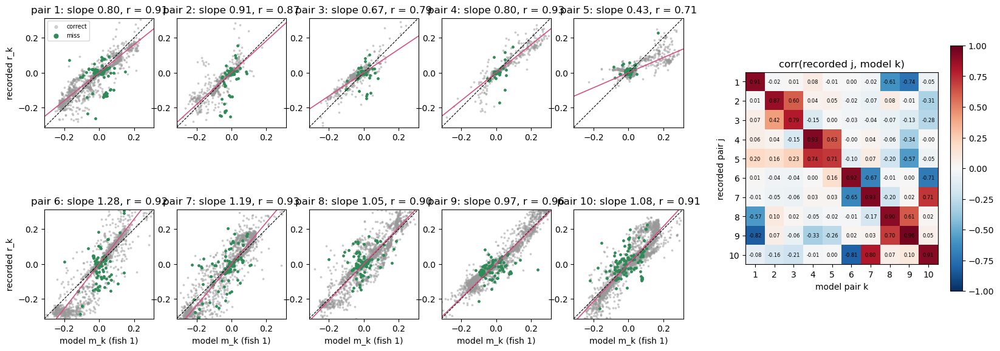

In [3]:
s = np.sign(np.einsum('nk,nk->n', R, U[:, EMITTER]))
M = G0 * s[:, None] * U[:, EMITTER]                               # fish 1 model in recorded units, best sign
slope = (R * M).sum(0) / (M ** 2).sum(0)
z = lambda X: (X - X.mean(0)) / X.std(0)
C = z(R).T @ z(M) / n                                             # corr(recorded pair j, model pair k)
per_pair = pd.DataFrame({'slope r_k / m_k': slope, 'corr(r_k, m_k)': np.diag(C),
                         'best-matching model pair': [pair_ids[k] for k in C.argmax(1)],
                         'median |r_k|': np.median(np.abs(R), 0)}, index=pd.Index(pair_ids, name='pair'))
display(per_pair.round(3))

fig = plt.figure(figsize=(20, 7.5))
gs = fig.add_gridspec(2, 7, width_ratios=[1, 1, 1, 1, 1, 0.15, 2.2])
lim = np.percentile(np.abs(np.r_[R.ravel(), M.ravel()]), 99.5)
for k, pid in enumerate(pair_ids):
    a = fig.add_subplot(gs[k // 5, k % 5])
    a.scatter(M[~miss, k], R[~miss, k], s=3, color='0.6', alpha=0.4, label='correct')
    a.scatter(M[miss, k], R[miss, k], s=6, color='#2E8B57', label='miss')
    a.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8); a.plot([-lim, lim], [-lim * slope[k], lim * slope[k]], color='#D45087', lw=1.2)
    a.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal', title=f'pair {pid}: slope {slope[k]:.2f}, r = {C[k, k]:.2f}')
    if k % 5 == 0: a.set_ylabel('recorded r_k')
    if k >= 5: a.set_xlabel('model m_k (fish 1)')
    if k == 0: a.legend(fontsize=7, markerscale=2)
a = fig.add_subplot(gs[:, 6])
im = a.imshow(C, cmap='RdBu_r', vmin=-1, vmax=1)
a.set(xticks=range(len(pair_ids)), xticklabels=pair_ids, yticks=range(len(pair_ids)), yticklabels=pair_ids,
      xlabel='model pair k', ylabel='recorded pair j', title='corr(recorded j, model k)')
for j in range(len(pair_ids)):
    for k in range(len(pair_ids)): a.text(k, j, f'{C[j, k]:.2f}', ha='center', va='center', fontsize=6)
plt.colorbar(im, ax=a, shrink=0.7); plt.show()

**Does the per-pair gain mismatch cost accuracy?** Divide each recorded pair by its slope (gain correction) and re-run the shape-only
rule. The slopes are fitted on fish 1 as emitter, i.e. with the answer known, so they are fitted on the first half of the recording
(by time) and tested on the second half, and the other way round.

In [4]:
def gain_slopes(sel):
    '''Per-pair slope recorded / model (fish 1 as emitter) fitted on the EODs in sel.'''
    return (R[sel] * M[sel]).sum(0) / (M[sel] ** 2).sum(0)

first = (res.time < res.time.median()).to_numpy()
R_cv = R.copy()
for fit, test in ((first, ~first), (~first, first)):
    R_cv[test] = R[test] / gain_slopes(fit)
gains = pd.DataFrame({'first half': gain_slopes(first), 'second half': gain_slopes(~first)}, index=pd.Index(pair_ids, name='pair'))
display(gains.round(2).T)
display(pd.Series({'raw recording': shape_correct(R), 'gain-corrected (fit on the other half)': shape_correct(R_cv),
                   'gain-corrected (fit on all, optimistic)': shape_correct(R / slope)}, name='% correct (shape only)').round(2).to_frame())

pair,1,2,3,4,5,6,7,8,9,10
first half,0.82,0.89,0.76,0.74,0.21,1.28,1.16,1.00,0.92,1.14
second half,0.79,0.93,0.63,0.81,0.55,1.29,1.24,1.09,1.00,0.99


,% correct (shape only)
raw recording,96.01
gain-corrected (fit on the other half),95.50
"gain-corrected (fit on all, optimistic)",95.84


## Assignment vs distance between the two fish

`N_DIST` random EODs from the good frames (ZEUS mask QC and SLEAP). Distance between the fish = smallest distance between the two
masks (px, edge to edge). For each distance bin (equal numbers of EODs), the fraction assigned to fish 1, the emitter, by
- **my pipeline**: shape-only rule (`assign_eod`), e = 0;
- **Denis' pipeline**: `discharging_fish` of `Assigned_Data_1fish_*.csv`. His fish A/B is mapped to a mask per EOD: the mask that
  holds the confident (score > 0.5) head, mouth and middle keypoints of the fish he picked. EODs where those keypoints are on neither
  mask are left out of his curve.

Error bars: 95% Wilson interval.

In [5]:
import pickle
from scipy.spatial import cKDTree
import mask_metrics as mm
%matplotlib inline

TRACK_PKL = 'data/2_fish_silent/elephantnose_20240213T143321_tracking_final.pkl'
DENIS_CSV = 'results/eod_assignment_2_fish_silent/Assigned_Data_1fish_2024-02-13T14_33_21.csv'
N_DIST, SEED, N_BINS = 1000, 0, 10
KP, KP_SCORE = ('head', 'mouth', 'middle'), 0.5

with open(TRACK_PKL, 'rb') as f:
    frames = pickle.load(f)['frames']

def frame_crops(k):
    '''{fish label: (box (y0, y1, x0, x1), bool crop)} of one tracked frame, remnant labels dropped.'''
    fr = frames[k]
    return {l: (b, mm.unpack_crop(p, b)) for l, p, b in zip(fr['labels'], fr['masks'], fr['boxes']) if l in FISH}

def gap_px(crops):
    '''Smallest distance (px) between the masks of fish 0 and fish 1.'''
    pts = [np.argwhere(c) + (b[0], b[2]) for b, c in (crops[f] for f in FISH)]
    return cKDTree(pts[0]).query(pts[1])[0].min()

def mask_of(row, X, crops):
    '''Mask label holding most confident keypoints of Denis' fish X in this row (-1 if none is on a mask).'''
    votes = []
    for p in KP:
        if not row[f'score_{p}_{X}'] > KP_SCORE: continue
        x, y = int(round(row[f'{p}_x_{X}'])), int(round(row[f'{p}_y_{X}']))
        votes += [l for l, ((y0, y1, x0, x1), c) in crops.items() if y0 <= y < y1 and x0 <= x < x1 and c[y - y0, x - x0]]
    return max(set(votes), key=votes.count) if votes else -1

den = pd.read_csv(DENIS_CSV, usecols=lambda c: not c.startswith('electrode_'))
assert len(den) == len(df_eod) and (den.Frame.to_numpy() == df_eod.Frame.to_numpy()).all()    # same rows, same order

pick = res.index[np.sort(np.random.default_rng(SEED).choice(n, N_DIST, replace=False))]
rows = []
for i in pick:
    crops = frame_crops(int(res.frame[i])); d = den.loc[i]
    rows.append(dict(row=i, frame=int(res.frame[i]), gap_px=gap_px(crops), mine=rules.at[i, 'fish | shape only'],
                     denis_fish=d.discharging_fish, denis=mask_of(d, d.discharging_fish, crops),
                     A_on=mask_of(d, 'A', crops), B_on=mask_of(d, 'B', crops)))
dist = pd.DataFrame(rows).set_index('row')
dist.to_csv(f'{OUT}/assignment_vs_distance_1000.csv')
print(f"Denis' fish A on mask: {dist.A_on.value_counts().to_dict()} | fish B on mask: {dist.B_on.value_counts().to_dict()}")
print(f"Denis' choice mapped to a mask for {(dist.denis >= 0).sum()} / {len(dist)} EODs")
print(f"% fish 1 over these {len(dist)} EODs: mine {100 * (dist.mine == 1).mean():.2f}% | "
      f"Denis {100 * (dist.denis[dist.denis >= 0] == 1).mean():.2f}%")

Denis' fish A on mask: {1: 1000} | fish B on mask: {0: 999, 1: 1}
Denis' choice mapped to a mask for 1000 / 1000 EODs
% fish 1 over these 1000 EODs: mine 95.70% | Denis 95.50%


my pipeline (shape only)                               \
                            median gap (px)    n n fish 1 % fish 1    lo   
bin                                                                        
(7.999, 77.042]                        41.8  100       89     89.0  81.4   
(77.042, 191.805]                     132.5  100       89     89.0  81.4   
(191.805, 337.355]                    274.8  100       99     99.0  94.6   
(337.355, 458.18]                     399.6  100       96     96.0  90.2   
(458.18, 545.224]                     510.8  100       97     97.0  91.5   
(545.224, 566.865]                    555.7  100       99     99.0  94.6   
(566.865, 622.748]                    589.8  100       99     99.0  94.6   
(622.748, 721.639]                    665.6  100       97     97.0  91.5   
(721.639, 797.033]                    757.7  100       97     97.0  91.5   
(797.033, 940.91]                     859.4  100       95     95.0  88.8   

                         Denis' pipeline                                     
                      hi median gap (px)    n n fish 1 % fish 1    lo    hi  
bin                                                                          
(7.999, 77.042]     93.7            41.8  100       95     95.0  88.8  97.8  
(77.042, 191.805]   93.7           132.5  100       95     95.0  88.8  97.8  
(191.805, 337.355]  99.8           274.8  100       94     94.0  87.5  97.2  
(337.355, 458.18]   98.4           399.6  100       98     98.0  93.0  99.4  
(458.18, 545.224]   99.0           510.8  100       95     95.0  88.8  97.8  
(545.224, 566.865]  99.8           555.7  100       96     96.0  90.2  98.4  
(566.865, 622.748]  99.8           589.8  100       99     99.0  94.6  99.8  
(622.748, 721.639]  99.0           665.6  100       95     95.0  88.8  97.8  
(721.639, 797.033]  99.0           757.7  100       95     95.0  88.8  97.8  
(797.033, 940.91]   97.8           859.4  100       93     93.0  86.3  96.6

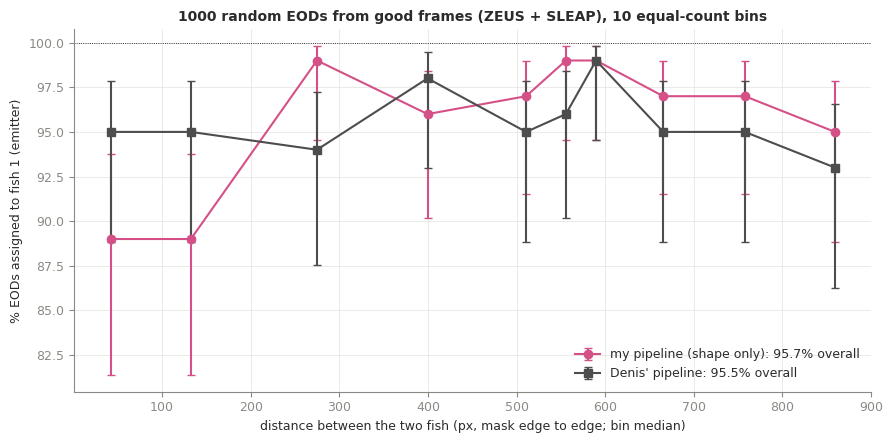

In [6]:
def wilson(k, m, z=1.96):
    '''95% Wilson interval of k successes in m trials, in %.'''
    p = k / m; c = (p + z ** 2 / (2 * m)) / (1 + z ** 2 / m); h = z * np.sqrt(p * (1 - p) / m + z ** 2 / (4 * m ** 2)) / (1 + z ** 2 / m)
    return 100 * (c - h), 100 * (c + h)

dist['bin'] = pd.qcut(dist.gap_px, N_BINS)
curves = {}
for name, col, sel in (('my pipeline (shape only)', 'mine', dist.mine >= 0), ("Denis' pipeline", 'denis', dist.denis >= 0)):
    g = dist[sel].groupby('bin', observed=True)
    t = pd.DataFrame({'median gap (px)': g.gap_px.median(), 'n': g.size(), 'n fish 1': g[col].apply(lambda s: (s == 1).sum())})
    t['% fish 1'] = 100 * t['n fish 1'] / t.n
    t['lo'], t['hi'] = wilson(t['n fish 1'], t.n)
    curves[name] = t
display(pd.concat(curves, axis=1).round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, t), col, mk in zip(curves.items(), ('#D45087', '0.3'), ('o', 's')):
    ax.errorbar(t['median gap (px)'], t['% fish 1'], yerr=[t['% fish 1'] - t.lo, t.hi - t['% fish 1']], fmt=f'{mk}-', color=col,
                capsize=3, label=f"{name}: {100 * t['n fish 1'].sum() / t.n.sum():.1f}% overall")
ax.axhline(100, color='k', lw=0.6, ls=':')
ax.set(xlabel='distance between the two fish (px, mask edge to edge; bin median)', ylabel='% EODs assigned to fish 1 (emitter)',
       title=f'{len(dist)} random EODs from good frames (ZEUS + SLEAP), {N_BINS} equal-count bins')
ax.legend(); plt.tight_layout(); fig.savefig(f'{OUT}/assignment_vs_distance_1000.png', dpi=110); plt.show()

## Examples with the two fish far apart: my model vs Denis' model

EODs from the good frames with the fish more than `FAR_PX` apart (mask edge to edge): `N_EX` assigned correctly (to fish 1) and
`N_EX` assigned wrongly (to fish 0) by my pipeline (shape only), chosen at random. Denis' assignment is in each title.

Left: video frame with both masks (green = fish 0, pink = fish 1), **my midline** (from the mask, head = gold dot), **Denis' midline**
(`currents_locations`: spline through the SLEAP mouth, head, middle and tail; white dashed, head = white square) and the **4 SLEAP
keypoints** he uses (mouth ▲, head ●, middle ■, tail ✕). Electrodes: + red, − blue, labelled with their pair number. Denis' coordinates are in cm, converted with his `pixel2cm` (912 px = 60 cm).

Right: one panel per electrode pair, one row per fish, three traces each, every one scaled to max |v| = 1 (per fish):
- **recorded** (black): the 25-sample window divided by its |value| at the peak sample;
- **my model** (colour): unit-current pair voltages of that fish, divided by their max |v|, with the best sign (as in the shape-only
  comparison);
- **Denis' model** (grey dashed): his `normalized_predicted_PTP` for that fish. He compares peak-to-peak values with a signed cosine
  similarity, so his sign is kept, and turned into the peak-sample convention with the sign relating his `recorded_PTP` to the
  recording at the peak sample.

My model and Denis' predict one number per pair; it is drawn as that number times the recording's own EOD waveform (rank-1, 1 at the
peak sample). Titles: my L2 distance (smaller = better) and Denis' cosine similarity (larger = better) for that fish.

2230 good EODs with the fish > 400 px apart: 50 wrong by my pipeline (2.2%)


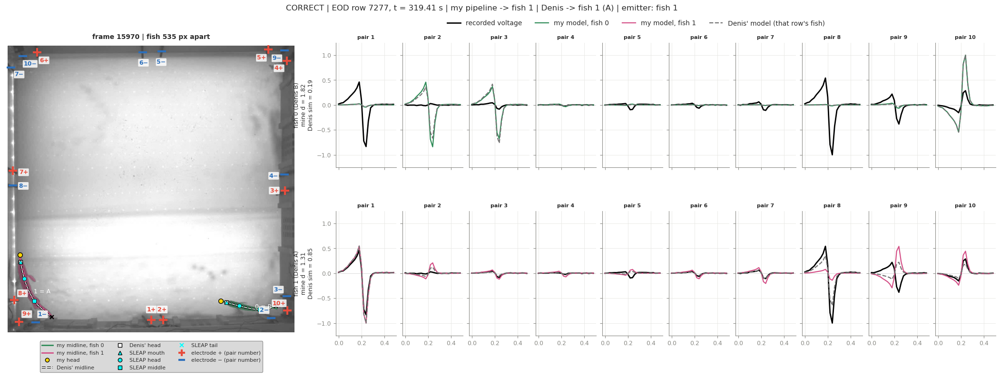

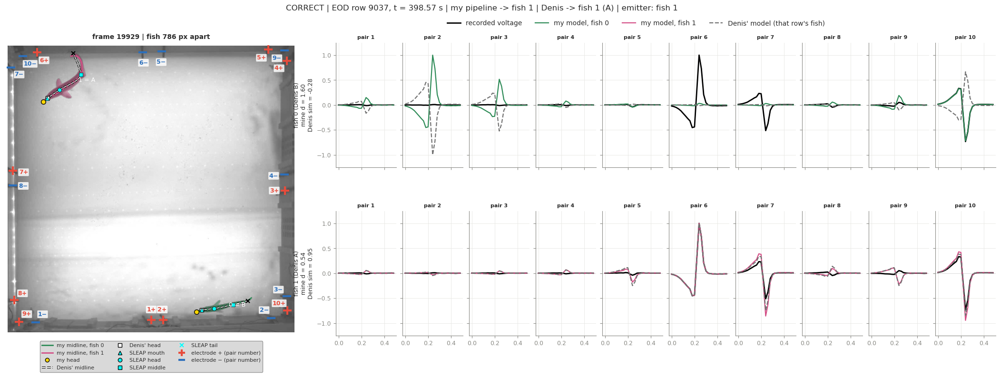

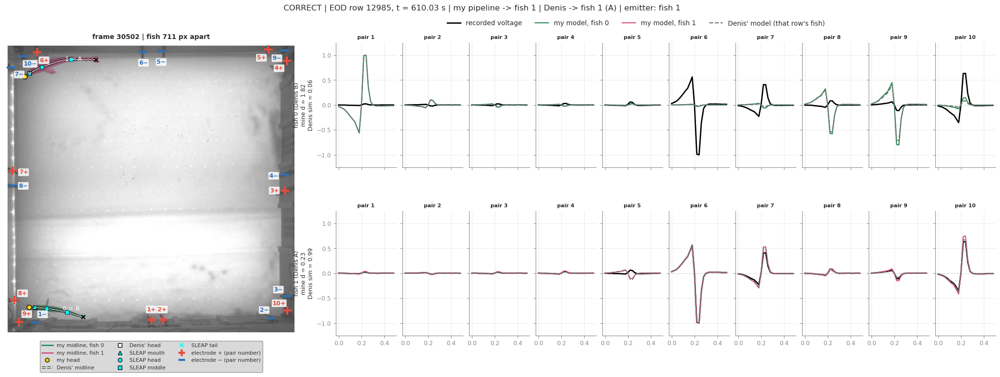

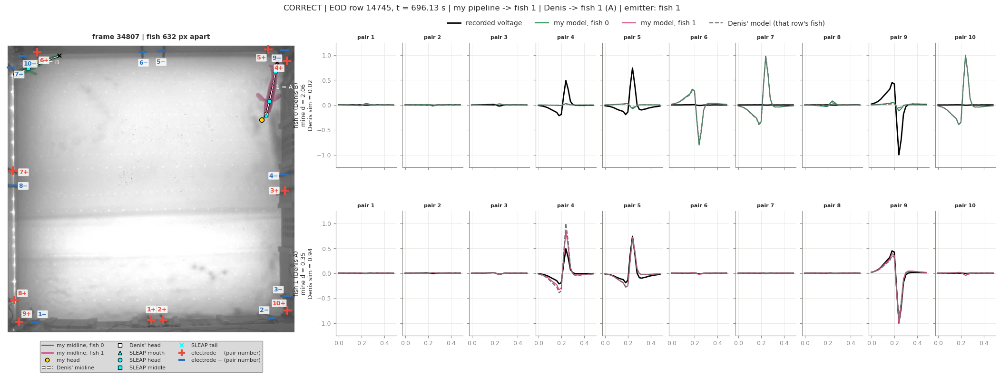

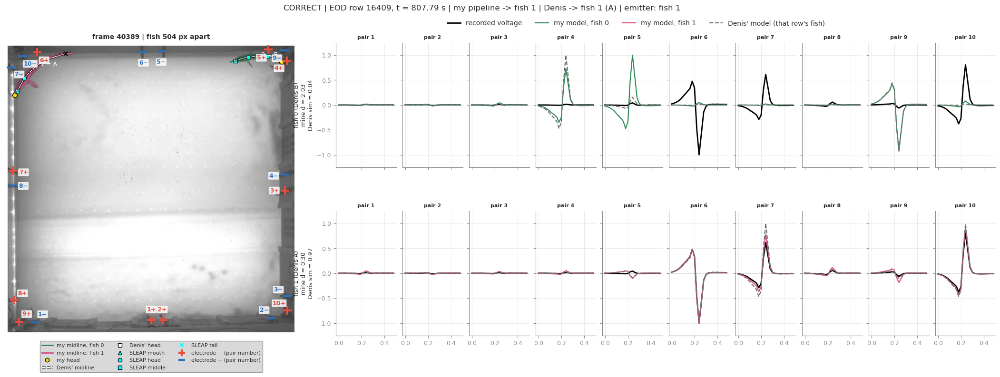

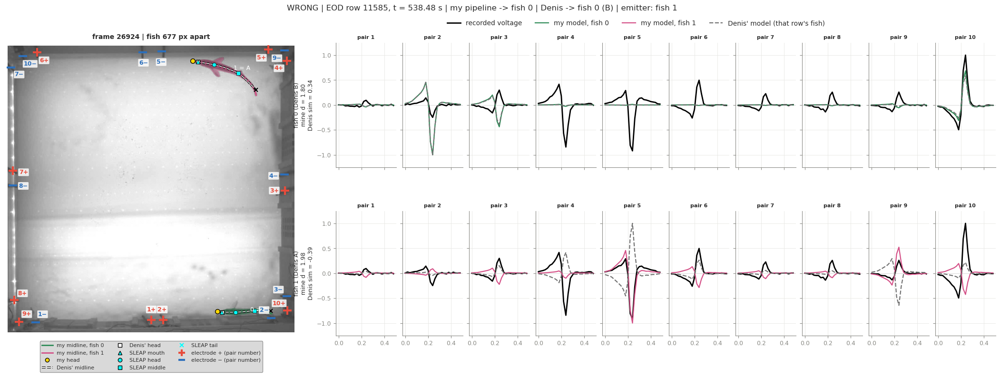

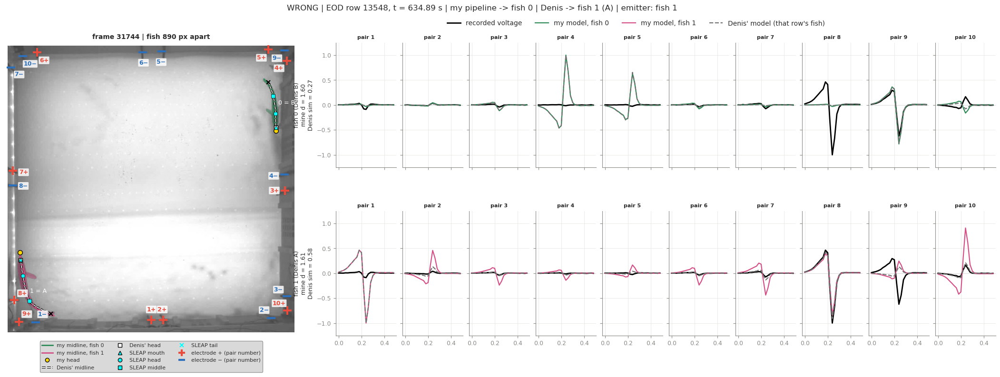

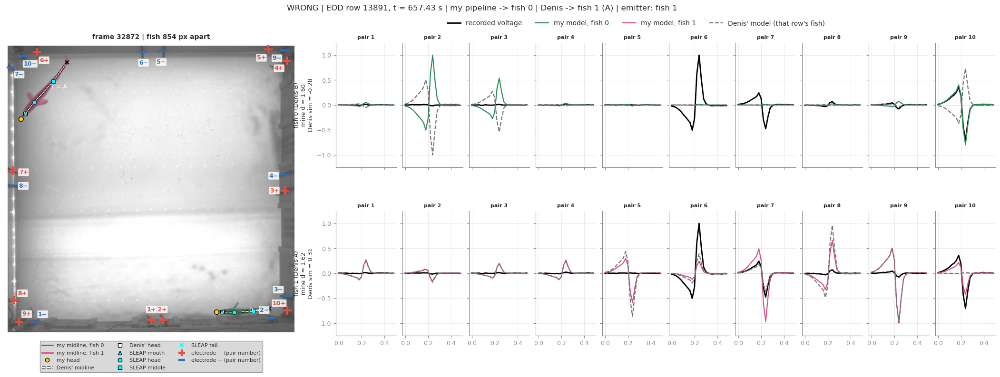

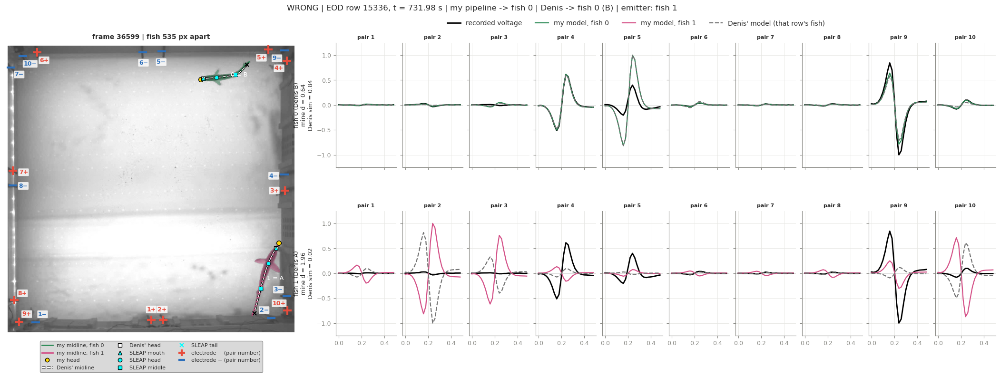

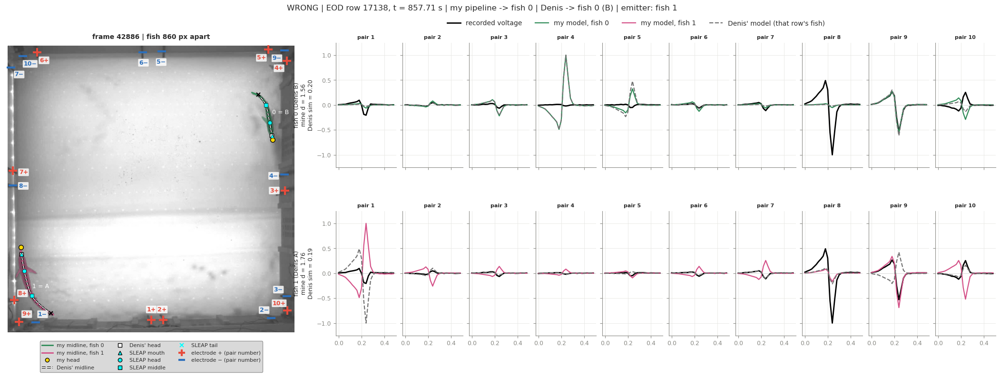

In [7]:
import os, subprocess
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
OUTLINE = [pe.withStroke(linewidth=3, foreground='k')]
from midline_methods import fish_midline_with_head

DENIS_PKL = 'results/eod_assignment_2_fish_silent/Assigned_Data_1fish_2024-02-13T14_33_21.pkl'
VIDEO = 'data/2_fish_silent/video2024-02-13T14_33_21.avi'
FAR_PX, N_EX = 400, 5
PX_PER_CM = 912 / 60                                              # Denis' pixel2cm calibration
FIG_DIR = f'{OUT}/debug_far_examples'; os.makedirs(FIG_DIR, exist_ok=True)

den_pkl = pd.read_pickle(DENIS_PKL)
assert len(den_pkl) == len(df_eod) and (den_pkl.Frame.to_numpy() == df_eod.Frame.to_numpy()).all()

gap_all = pd.Series({i: gap_px(frame_crops(int(res.frame[i]))) for i in res.index}, name='gap_px')
far = gap_all.index[gap_all > FAR_PX]
rng = np.random.default_rng(SEED)
ex_ok = np.sort(rng.choice(far[~miss[res.index.get_indexer(far)]], N_EX, replace=False))
ex_bad = np.sort(rng.choice(far[miss[res.index.get_indexer(far)]], N_EX, replace=False))
print(f"{len(far)} good EODs with the fish > {FAR_PX} px apart: {miss[res.index.get_indexer(far)].sum()} wrong by my pipeline "
      f"({100 * miss[res.index.get_indexer(far)].mean():.1f}%)")

def frame_masks(k):
    '''(n_fish, P, P) full-frame bool masks of frame k.'''
    m = np.zeros((len(FISH), P, P), bool)
    for l, ((y0, y1, x0, x1), c) in frame_crops(k).items(): m[l, y0:y1, x0:x1] = c
    return m

def video_frame(k):
    '''Grayscale (P, P) frame k of the raw video (ffmpeg).'''
    out = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{k / 50:.4f}', '-i', VIDEO, '-frames:v', '1', '-f', 'rawvideo',
                          '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(out, np.uint8).reshape(P, P)

def plot_example(i, kind, Um=None, mine_fish=None, pairs_draw=None, fig_dir=None):
    '''Tank + per-pair traces of EOD row i. Um: my model voltages (n, fish, pairs) aligned with res (default: the cached run);
       mine_fish: my assignment per row (default: the saved one); pairs_draw: electrode polarity to draw.'''
    Um = U if Um is None else Um
    pairs_draw = pairs_orig if pairs_draw is None else pairs_draw
    fig_dir = FIG_DIR if fig_dir is None else fig_dir
    j, k = res.index.get_loc(i), int(res.frame[i])
    crops, fm, dr, dp = frame_crops(k), frame_masks(k), den.loc[i], den_pkl.loc[i]
    letter = {mask_of(dr, X, crops): X for X in 'AB'}                  # mask label -> Denis' fish
    assert sorted(letter) == list(FISH), letter
    Vi = V[j]; r = R[j]; rmax = np.abs(r).max()
    w = rank1_pattern(Vi)[1]; w = w / w[ts[j]]
    sigma = np.sign(dp.recorded_PTP @ r)                              # Denis' PTP sign -> peak-sample sign

    fig = plt.figure(figsize=(27, 8))
    gs = fig.add_gridspec(2, 12, width_ratios=[5, 0.35] + [1] * 10, wspace=0.08, hspace=0.35)
    a = fig.add_subplot(gs[:, 0])
    a.imshow(video_frame(k), cmap='gray')
    over = np.zeros((P, P, 4))
    for f in FISH:
        over[fm[f]] = to_rgba(FISH_COLOR[f], 0.4)
        mid = fish_midline_with_head(fm[f], n_ctrl=101)['midline'] * (P - 1)          # (row, col), tail -> head
        a.plot(mid[:, 1], mid[:, 0], color=FISH_COLOR[f], lw=1.8)
        a.plot(mid[-1, 1], mid[-1, 0], 'o', color='gold', mec='k', ms=7)
        X = letter[f]
        dm = np.asarray(dp[f'currents_locations_{X}']) * PX_PER_CM                     # (x, y) px, tail -> mouth
        a.plot(dm[:, 0], dm[:, 1], color='w', lw=1.2, ls='--', path_effects=OUTLINE)
        a.plot(dm[-1, 0], dm[-1, 1], 's', color='w', mec='k', ms=6)
        for kp, mk in (('mouth', '^'), ('head', 'o'), ('middle', 's'), ('tail', 'x')):
            x, y = np.asarray(dp[f'{kp}_{X}']) * PX_PER_CM
            a.plot(x, y, mk, color='cyan', mec='k', ms=6, mew=1.5 if mk == 'x' else 0.5)
        a.text(*dm[len(dm) // 2], f'  {f} = {X}', color='w', fontsize=9)
    a.imshow(over); a.set_axis_off()
    for pid, pp, pm in pairs_draw:                                    # electrodes, labelled pair + polarity
        for pt, sgn, col, mk in ((pp, '+', '#E74C3C', '+'), (pm, '−', '#2C6FBB', '_')):
            y, x = pt * (P - 1)
            a.plot(x, y, mk, color=col, ms=13, mew=3)
            off = np.array([P / 2 - x, P / 2 - y]); off = 34 * off / np.linalg.norm(off)
            a.text(x + off[0], y + off[1], f'{pid}{sgn}', color=col, fontsize=9, fontweight='bold', ha='center', va='center',
                   bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=0.85))
    a.set(xlim=(-10, P + 10), ylim=(P + 10, -10))
    a.set_title(f"frame {k} | fish {gap_all[i]:.0f} px apart", fontsize=10)
    a.legend(handles=[Line2D([], [], color=FISH_COLOR[0], lw=2, label='my midline, fish 0'),
                      Line2D([], [], color=FISH_COLOR[1], lw=2, label='my midline, fish 1'),
                      Line2D([], [], marker='o', color='gold', mec='k', ls='', label='my head'),
                      Line2D([], [], color='w', lw=1.5, ls='--', path_effects=OUTLINE, label="Denis' midline"),
                      Line2D([], [], marker='s', color='w', mec='k', ls='', label="Denis' head"),
                      Line2D([], [], marker='^', color='cyan', mec='k', ls='', label='SLEAP mouth'),
                      Line2D([], [], marker='o', color='cyan', mec='k', ls='', label='SLEAP head'),
                      Line2D([], [], marker='s', color='cyan', mec='k', ls='', label='SLEAP middle'),
                      Line2D([], [], marker='x', color='cyan', mec='cyan', mew=1.5, ls='', label='SLEAP tail'),
                      Line2D([], [], marker='+', color='#E74C3C', ms=10, mew=3, ls='', label='electrode + (pair number)'),
                      Line2D([], [], marker='_', color='#2C6FBB', ms=10, mew=3, ls='', label='electrode − (pair number)')],
             loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=3, fontsize=8, frameon=True, facecolor='0.85',
             edgecolor='0.6', framealpha=1)

    for f in FISH:
        X = letter[f]
        u = Um[j, f] / np.abs(Um[j, f]).max(); u = u * np.sign(u @ r)
        pd_hat = sigma * np.asarray(dp[f'normalized_predicted_PTP_{X}'])
        d_mine = compare_patterns(Um[j, f], r)[0]
        for kk, pid in enumerate(pair_ids):
            ax = fig.add_subplot(gs[f, 2 + kk])
            ax.axhline(0, color='0.85', lw=0.6)
            ax.plot(t_ms, Vi[kk] / rmax, color='k', lw=2, label='recorded')
            ax.plot(t_ms, u[kk] * w, color=FISH_COLOR[f], lw=1.6, label='my model')
            ax.plot(t_ms, pd_hat[kk] * w, color='0.45', lw=1.6, ls='--', label="Denis' model")
            ax.set_ylim(-1.25, 1.25); ax.set_title(f'pair {pid}', fontsize=8)
            if kk: ax.set_yticklabels([])
            else: ax.set_ylabel(f"fish {f} (Denis {X})\nmine d = {d_mine:.2f}\nDenis sim = {dp[f'similarity_{X}']:.2f}", fontsize=9)
            if f == 0: ax.set_xticklabels([])
    mine_f = rules.at[i, 'fish | shape only'] if mine_fish is None else mine_fish[i]
    den_f = {v: kk for kk, v in letter.items()}[dr.discharging_fish]
    fig.suptitle(f"{kind.upper()} | EOD row {i}, t = {res.time[i]:.2f} s | my pipeline -> fish {mine_f} | "
                 f"Denis -> fish {den_f} ({dr.discharging_fish}) | emitter: fish 1", fontsize=12)
    fig.legend(handles=[Line2D([], [], color='k', lw=2, label='recorded voltage'),
                        Line2D([], [], color=FISH_COLOR[0], lw=1.6, label='my model, fish 0'),
                        Line2D([], [], color=FISH_COLOR[1], lw=1.6, label='my model, fish 1'),
                        Line2D([], [], color='0.45', lw=1.6, ls='--', label="Denis' model (that row's fish)")],
               loc='upper center', bbox_to_anchor=(0.62, 0.955), ncol=4, fontsize=10, frameon=False)
    fig.savefig(f"{fig_dir}/{kind.replace(' ', '_')}_eod{i}_frame{k}.png", dpi=100, bbox_inches='tight'); plt.show()

for kind, ids in (('correct', ex_ok), ('wrong', ex_bad)):
    for i in ids: plot_example(i, kind)

## Where Denis puts the sink, along the body

Denis' point currents (`currents_locations`) follow a spline through the SLEAP tail, middle, head and mouth keypoints; the first point,
the **SLEAP tail keypoint**, is the sink (−100, the other 100 points +1 each). Here, for `N_SINK` random good frames (ZEUS and SLEAP)
and both fish, the SLEAP tail keypoint is placed on my midline (from the mask, tail tip → head): its position is the arc length from my
tail tip to the nearest midline point, in % of my midline length. Also given: its distance from my tail tip and from the midline (px).
Denis' fish A/B is matched to a mask by his mouth, head and middle keypoints, as above.

100 frames, 200 fish (Denis' fish matched to a mask)


fish                            0       1
pct_body            count  100.00  100.00
                    mean     6.19    5.77
                    std      9.82    2.72
                    min      0.00    0.00
                    10%      0.00    3.00
                    25%      3.00    4.00
                    50%      6.00    5.00
                    75%      8.00    7.00
                    90%      9.10    9.00
                    max     97.00   15.00
from_my_tail_tip_px count  100.00  100.00
                    mean    12.64   14.84
                    std     15.71    6.53
                    min      1.33    2.28
                    10%      4.01    8.02
                    25%      6.93   10.59
                    50%     11.03   14.00
                    75%     14.42   17.87
                    90%     18.71   23.39
                    max    157.34   39.30
off_midline_px      count  100.00  100.00
                    mean     3.46    2.13
                    std      3.35    1.44
                    min      0.18    0.23
                    10%      0.74    0.49
                    25%      1.33    1.15
                    50%      2.77    1.71
                    75%      4.42    2.88
                    90%      6.19    4.02
                    max     21.09    7.46
body_px             count  100.00  100.00
                    mean   173.58  247.74
                    std      9.66    6.61
                    min    144.35  225.13
                    10%    161.83  241.34
                    25%    168.78  245.40
                    50%    175.78  248.57
                    75%    179.48  251.90
                    90%    183.02  255.15
                    max    198.86  260.91
score_tail          count  100.00  100.00
                    mean     0.66    0.72
                    std      0.13    0.16
                    min      0.34    0.30
                    10%      0.52    0.53
                    25%      0.58    0.62
                    50%      0.65    0.71
                    75%      0.75    0.85
                    90%      0.82    0.91
                    max      1.01    1.08

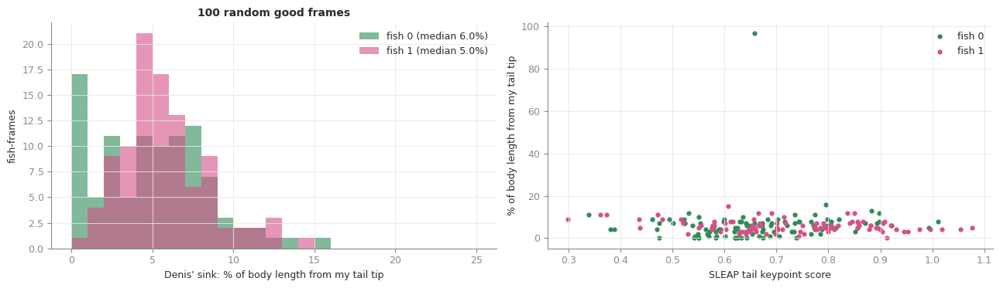

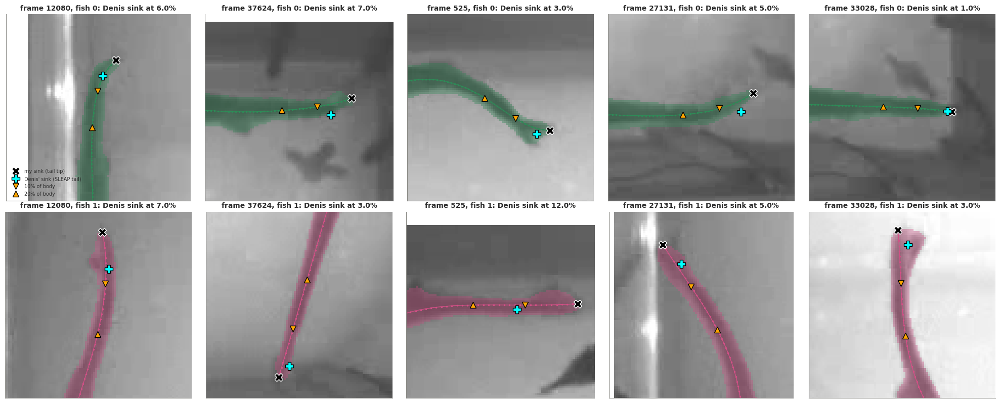

In [8]:
N_SINK = 100
sink_frames = np.sort(np.random.default_rng(SEED).choice(res.frame.unique(), N_SINK, replace=False))
row_of = res.reset_index().drop_duplicates('frame').set_index('frame')['row']       # one EOD row per frame (same keypoints)
rows = []
for k in sink_frames:
    i = row_of[k]; crops = frame_crops(int(k)); fm_k = frame_masks(int(k))
    for X in 'AB':
        f = mask_of(den.loc[i], X, crops)
        if f < 0: continue
        mid = fish_midline_with_head(fm_k[f], n_ctrl=101)['midline'] * (P - 1)        # (row, col) px, tail tip -> head
        arc = np.r_[0, np.cumsum(np.linalg.norm(np.diff(mid, axis=0), axis=1))]
        tail = (np.asarray(den_pkl.at[i, f'tail_{X}']) * PX_PER_CM)[::-1]             # Denis' sink, (row, col) px
        j = np.argmin(np.linalg.norm(mid - tail, axis=1))
        rows.append(dict(frame=k, row=i, fish=f, denis=X, pct_body=100 * arc[j] / arc[-1],
                         from_my_tail_tip_px=np.linalg.norm(tail - mid[0]), off_midline_px=np.linalg.norm(tail - mid[j]),
                         body_px=arc[-1], score_tail=den.at[i, f'score_tail_{X}']))
sink = pd.DataFrame(rows)
sink.to_csv(f'{OUT}/denis_sink_position_{N_SINK}frames.csv', index=False)
print(f"{sink.frame.nunique()} frames, {len(sink)} fish (Denis' fish matched to a mask)")
display(sink.groupby('fish')[['pct_body', 'from_my_tail_tip_px', 'off_midline_px', 'body_px', 'score_tail']]
        .describe(percentiles=[.1, .25, .5, .75, .9]).T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for f in FISH:
    s = sink[sink.fish == f]
    ax[0].hist(s.pct_body, bins=np.arange(0, 26, 1), alpha=0.6, color=FISH_COLOR[f], label=f'fish {f} (median {s.pct_body.median():.1f}%)')
    ax[1].scatter(s.score_tail, s.pct_body, s=12, color=FISH_COLOR[f], label=f'fish {f}')
ax[0].set(xlabel="Denis' sink: % of body length from my tail tip", ylabel='fish-frames', title=f'{N_SINK} random good frames')
ax[0].legend(); ax[1].set(xlabel='SLEAP tail keypoint score', ylabel='% of body length from my tail tip'); ax[1].legend()
plt.tight_layout(); fig.savefig(f'{OUT}/denis_sink_position_{N_SINK}frames.png', dpi=110); plt.show()

ex = pd.concat([sink[sink.fish == f].sample(5, random_state=SEED) for f in FISH])
fig, ax = plt.subplots(2, 5, figsize=(20, 8))
for a, (_, e) in zip(ax.ravel(), ex.iterrows()):
    k, f, X = int(e.frame), int(e.fish), e.denis
    fm_k = frame_masks(k); mid = fish_midline_with_head(fm_k[f], n_ctrl=101)['midline'] * (P - 1)
    tail = (np.asarray(den_pkl.at[e.row, f'tail_{X}']) * PX_PER_CM)[::-1]
    c = mid[:30].mean(0); r0, c0 = (c - 45).astype(int); r1, c1 = (c + 45).astype(int)
    a.imshow(video_frame(k), cmap='gray'); a.imshow(np.where(fm_k[f][..., None], np.array(to_rgba(FISH_COLOR[f], 0.35)), 0))
    a.plot(mid[:, 1], mid[:, 0], '.-', color=FISH_COLOR[f], ms=3, lw=1)
    a.plot(mid[0, 1], mid[0, 0], 'X', color='k', mec='w', ms=11, label='my sink (tail tip)')
    a.plot(tail[1], tail[0], 'P', color='cyan', mec='k', ms=11, label="Denis' sink (SLEAP tail)")
    for s_, mk in ((0.1, 'v'), (0.2, '^')):
        q = mid[int(round(s_ * 100))]; a.plot(q[1], q[0], mk, color='orange', mec='k', ms=8, label=f'{s_:.0%} of body')
    a.set(xlim=(c0, c1), ylim=(r1, r0), xticks=[], yticks=[], title=f'frame {k}, fish {f}: Denis sink at {e.pct_body:.1f}%')
ax[0, 0].legend(fontsize=7, loc='lower left')
plt.tight_layout(); plt.show()

## New model: sink at 5% of body length, pairs 2 and 5 flipped

Two changes, everything else as before:
- `compute_electric_field.multipole_sources` now puts the sink at `SINK_FRAC` = 5% of the body length from the tail tip (about where
  Denis' sink, the SLEAP tail keypoint, lies); the +1 is spread over the points between it and the head, the points behind it carry
  no current;
- the polarity of pairs 2 and 5 is flipped (it was flipped in all electrode files for this run, then restored: this section flips
  it explicitly with `pairs_flipped`, and reads the voltages cached in that run).

The same `N_DIST` = 1000 random EODs as above are solved again (2 field solves each, in parallel) and assigned with the shape-only
rule. The model voltages go to the cache of the main notebook for this model (`model_cache_tag`). Flipping a pair's polarity only
negates that pair's model voltage, so the effect of each change alone is also shown, without new solves.

sink at 5%, electrode file data/electrodes_signed_px_coord_2024-02-13.csv | 0 of 1000 EODs in results/eod_ground_truth/model_voltages_N150_sink0.05_elc5c81b.pkl, 1000 to solve


,% fish 1 (shape only)
"sink at tail tip, original polarity (assignment run)",95.7
"sink at tail tip, pairs 2 and 5 flipped",90.1
"sink at 5%, original polarity",94.0
"sink at 5%, pairs 2 and 5 flipped (new model)",88.6
Denis' pipeline,95.5


my pipeline, new model                \
                          median gap (px)    n % fish 1   
bin                                                       
(7.999, 77.042]                      41.8  100     80.0   
(77.042, 191.805]                   132.5  100     81.0   
(191.805, 337.355]                  274.8  100     94.0   
(337.355, 458.18]                   399.6  100     88.0   
(458.18, 545.224]                   510.8  100     92.0   
(545.224, 566.865]                  555.7  100     94.0   
(566.865, 622.748]                  589.8  100     93.0   
(622.748, 721.639]                  665.6  100     92.0   
(721.639, 797.033]                  757.7  100     90.0   
(797.033, 940.91]                   859.4  100     82.0   

                   my pipeline, assignment run               Denis' pipeline  \
                               median gap (px)    n % fish 1 median gap (px)   
bin                                                                            
(7.999, 77.042]                           41.8  100     89.0            41.8   
(77.042, 191.805]                        132.5  100     89.0           132.5   
(191.805, 337.355]                       274.8  100     99.0           274.8   
(337.355, 458.18]                        399.6  100     96.0           399.6   
(458.18, 545.224]                        510.8  100     97.0           510.8   
(545.224, 566.865]                       555.7  100     99.0           555.7   
(566.865, 622.748]                       589.8  100     99.0           589.8   
(622.748, 721.639]                       665.6  100     97.0           665.6   
(721.639, 797.033]                       757.7  100     97.0           757.7   
(797.033, 940.91]                        859.4  100     95.0           859.4   

                                  
                      n % fish 1  
bin                               
(7.999, 77.042]     100     95.0  
(77.042, 191.805]   100     95.0  
(191.805, 337.355]  100     94.0  
(337.355, 458.18]   100     98.0  
(458.18, 545.224]   100     95.0  
(545.224, 566.865]  100     96.0  
(566.865, 622.748]  100     99.0  
(622.748, 721.639]  100     95.0  
(721.639, 797.033]  100     95.0  
(797.033, 940.91]   100     93.0

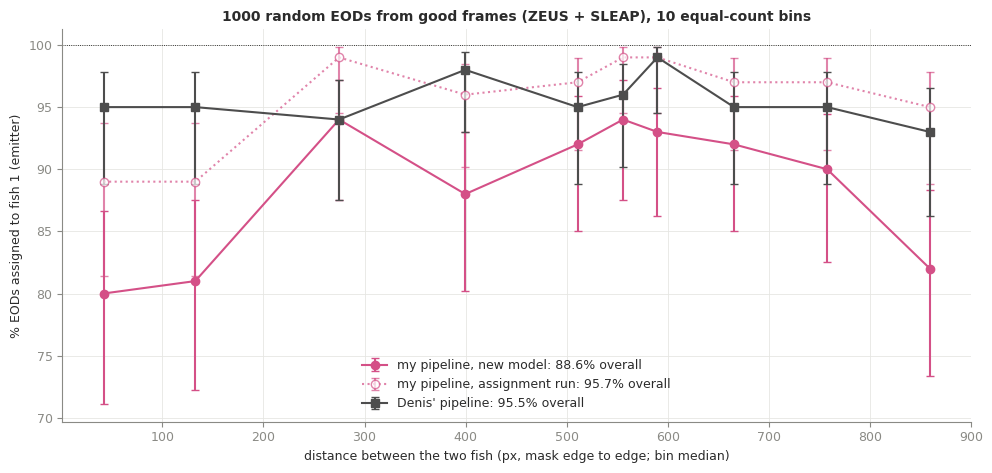

In [9]:
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from compute_electric_field import SINK_FRAC
from eod_assign import candidate_field, pair_voltages, peak_pattern, recorded_pair_traces, model_cache_tag

N, n_poles, delta_h = 150, 100, 0.5                      # field model of the assignment run
MAT = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=200.0, eps_interior=0.0, sigma_skin=0.05, eps_skin=2.7e-6)
N_WORKERS = 6
NEW_CACHE = f'{OUT}/model_voltages_N{N}_sink{SINK_FRAC:g}_elc5c81b.pkl'      # cached with pairs 2 and 5 flipped (file restored since)

def model_voltages(i):
    '''Cache record of EOD row i for the current model (multipole_sources, electrode files): recorded peak pattern and the
       unit-current pair voltages (fish, pairs) of each fish as the emitter.'''
    row = df_eod.loc[i]; fm_i = frame_masks(int(row.Frame))
    mids = [fish_midline_with_head(m, n_ctrl=n_poles + 1)['midline'] for m in fm_i]
    u = [pair_voltages(candidate_field(fm_i, f, mids[f], N, delta_h, MAT).real, pairs_flipped, N) for f in FISH]
    return dict(row=i, frame=int(row.Frame), time=row.Time, v_rec=peak_pattern(recorded_pair_traces(row, pair_ids, n_samp))[0],
                u=np.array(u), L=np.array([np.linalg.norm(np.diff(m, axis=0), axis=1).sum() for m in mids]))

cache_new = pd.read_pickle(NEW_CACHE) if os.path.exists(NEW_CACHE) else None
todo = list(pick if cache_new is None else pick.difference(cache_new.index))
print(f"sink at {SINK_FRAC:.0%}, pairs 2 and 5 flipped | {len(pick) - len(todo)} of {len(pick)} EODs in {NEW_CACHE}, "
      f"{len(todo)} to solve")
if todo:
    with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:
        new = pd.DataFrame(list(pool.map(model_voltages, todo, chunksize=4))).set_index('row')
    cache_new = new if cache_new is None else pd.concat([cache_new, new])
    cache_new.to_pickle(NEW_CACHE)

jp = res.index.get_indexer(pick)                          # positions of the 1000 EODs in res
U_new = np.full_like(U, np.nan); U_new[jp] = np.stack(cache_new.loc[pick].u)
assert np.allclose(np.stack(cache_new.loc[pick].v_rec), R[jp])
flip = np.where(np.isin(pair_ids, FLIPPED), -1.0, 1.0)    # polarity flip of pairs 2 and 5 = sign change of their voltages

def shape_fish(Um):
    '''Shape-only assignment (assign_eod's rule) of the 1000 EODs for model voltages Um (aligned with res).'''
    return pd.Series([min(FISH, key=lambda f: compare_patterns(Um[j, f], R[j])[0]) for j in jp], index=pick)

variants = {'sink at tail tip, original polarity (assignment run)': U, 'sink at tail tip, pairs 2 and 5 flipped': U * flip,
            f'sink at {SINK_FRAC:.0%}, original polarity': U_new * flip, f'sink at {SINK_FRAC:.0%}, pairs 2 and 5 flipped (new model)': U_new}
fish_v = {k: shape_fish(v) for k, v in variants.items()}
assert (fish_v['sink at tail tip, original polarity (assignment run)'] == dist.mine).all()
summary = pd.Series({k: 100 * (v == EMITTER).mean() for k, v in fish_v.items()}, name='% fish 1 (shape only)')
summary["Denis' pipeline"] = 100 * (dist.denis[dist.denis >= 0] == EMITTER).mean()
display(summary.round(2).to_frame())

NEW = f'sink at {SINK_FRAC:.0%}, pairs 2 and 5 flipped (new model)'
dist['mine_new'] = fish_v[NEW]
dist.to_csv(f'{OUT}/assignment_vs_distance_1000.csv')
curves_new = {}
for name, col, sel in ((f'my pipeline, new model', 'mine_new', dist.mine_new >= 0), ('my pipeline, assignment run', 'mine', dist.mine >= 0),
                       ("Denis' pipeline", 'denis', dist.denis >= 0)):
    g = dist[sel].groupby('bin', observed=True)
    t = pd.DataFrame({'median gap (px)': g.gap_px.median(), 'n': g.size(), 'n fish 1': g[col].apply(lambda s: (s == 1).sum())})
    t['% fish 1'] = 100 * t['n fish 1'] / t.n
    t['lo'], t['hi'] = wilson(t['n fish 1'], t.n)
    curves_new[name] = t
display(pd.concat({k: v[['median gap (px)', 'n', '% fish 1']] for k, v in curves_new.items()}, axis=1).round(1))

fig, ax = plt.subplots(figsize=(10, 4.8))
for (name, t), col, mk, ls in zip(curves_new.items(), ('#D45087', '#D45087', '0.3'), ('o', 'o', 's'), ('-', ':', '-')):
    ax.errorbar(t['median gap (px)'], t['% fish 1'], yerr=[t['% fish 1'] - t.lo, t.hi - t['% fish 1']], fmt=mk, ls=ls, color=col,
                mfc=col if ls == '-' else 'white', capsize=3, alpha=1 if ls == '-' else 0.7,
                label=f"{name}: {100 * t['n fish 1'].sum() / t.n.sum():.1f}% overall")
ax.axhline(100, color='k', lw=0.6, ls=':')
ax.set(xlabel='distance between the two fish (px, mask edge to edge; bin median)', ylabel='% EODs assigned to fish 1 (emitter)',
       title=f'{len(dist)} random EODs from good frames (ZEUS + SLEAP), {N_BINS} equal-count bins')
ax.legend(fontsize=9); plt.tight_layout(); fig.savefig(f'{OUT}/assignment_vs_distance_1000_new_model.png', dpi=110); plt.show()

### Fish far apart: correct and wrong for my new model and for Denis'

EODs among the 1000 with the fish more than `FAR_PX` apart, in four groups by who assigns them to fish 1 (correct): both pipelines,
only mine (new model), only Denis', neither. Up to `N_EX4` random EODs per group, drawn as above (my model = the new model;
electrodes drawn with the new polarity).

649 of the 1000 EODs have the fish > 400 px apart: both correct 570, only mine correct 18, only Denis correct 51, both wrong 10


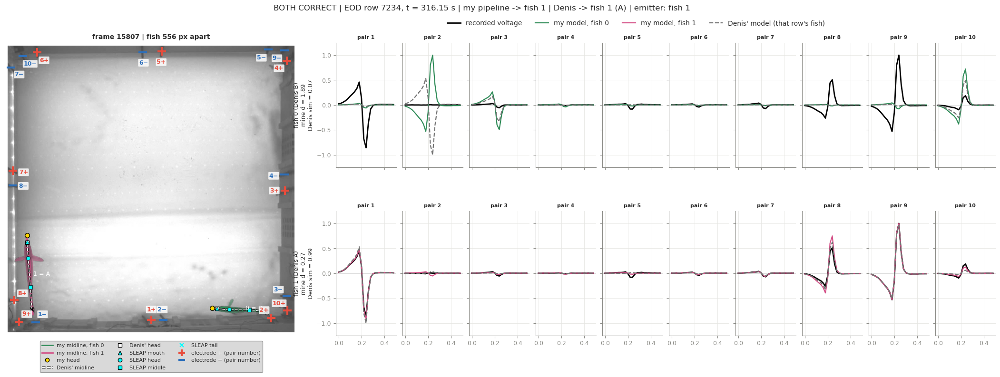

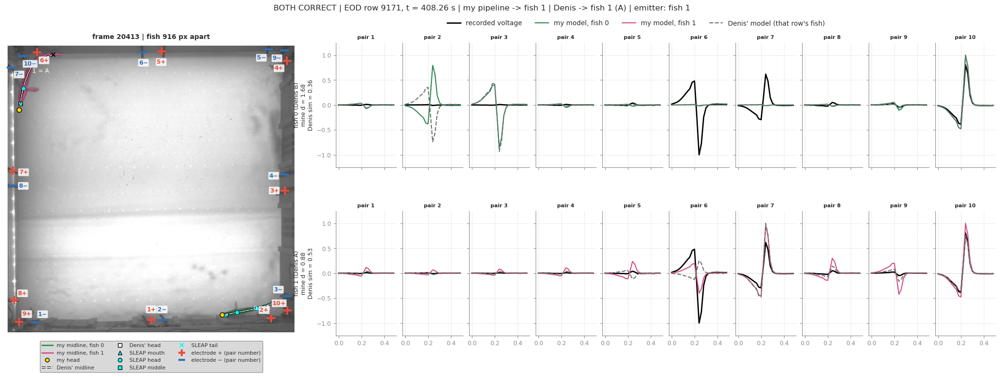

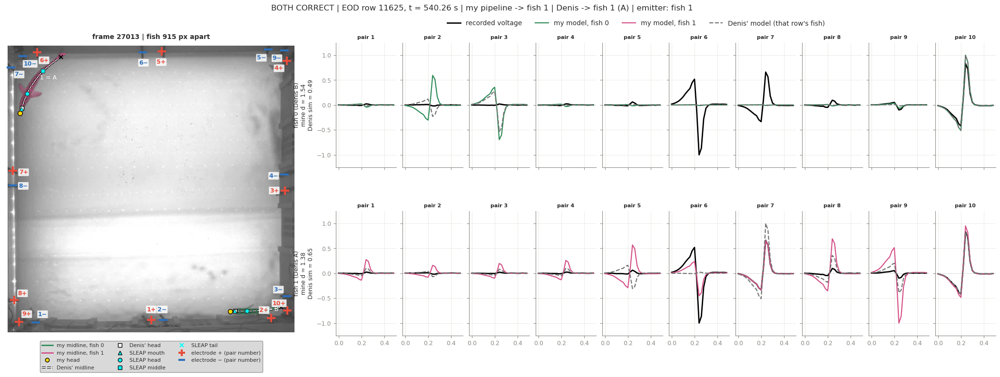

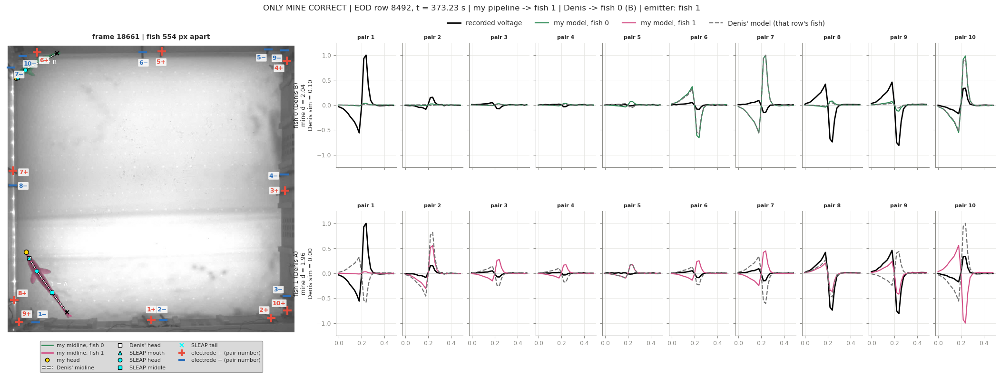

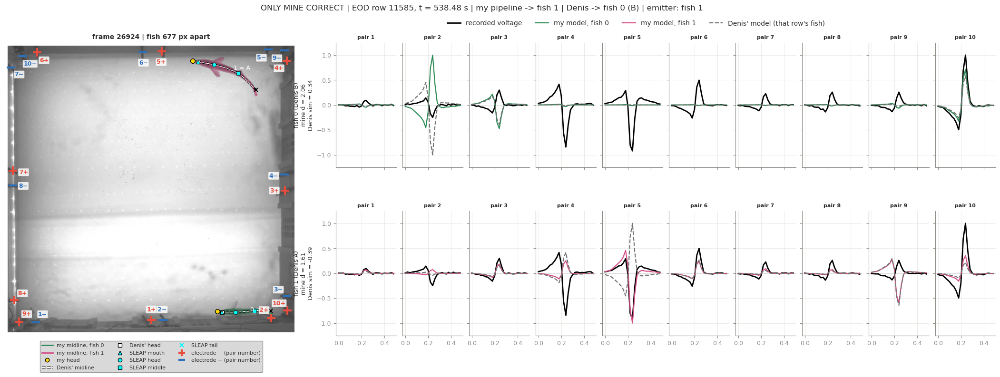

...

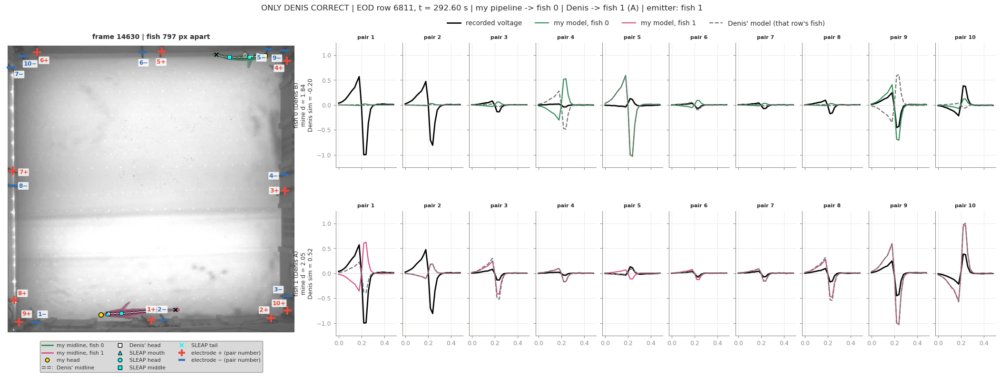

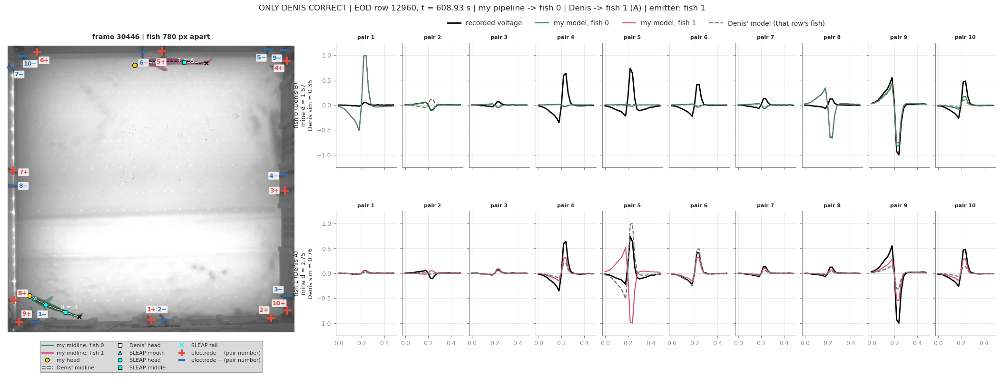

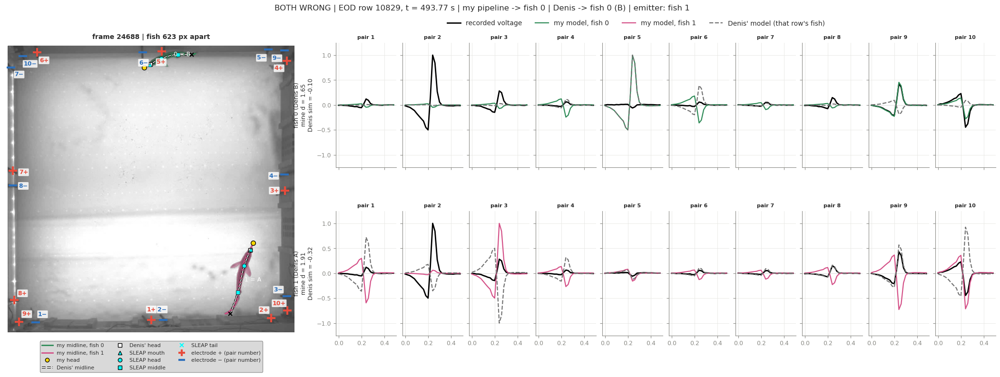

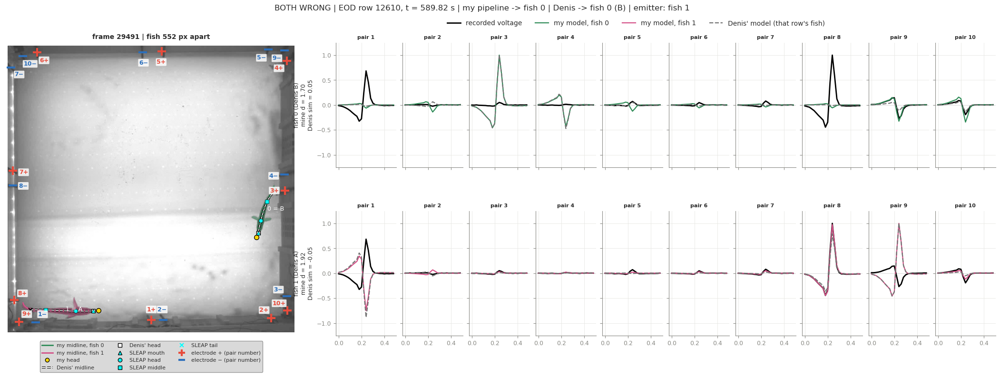

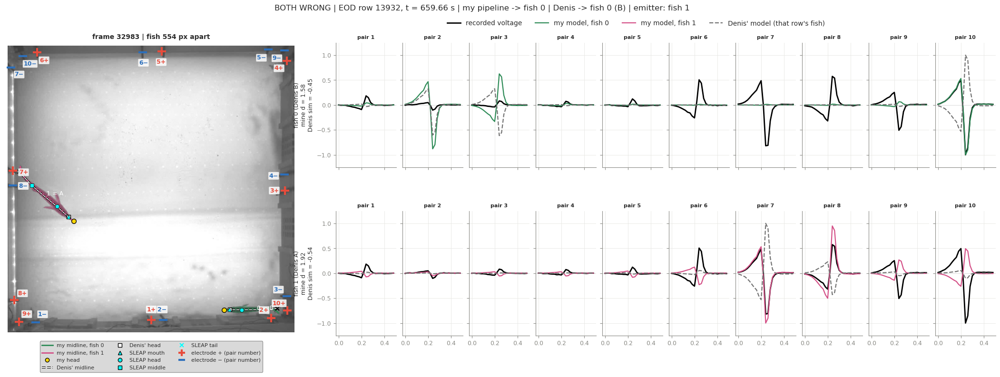

In [10]:
N_EX4 = 3
FIG_DIR_NEW = f'{OUT}/debug_far_examples_new_model'; os.makedirs(FIG_DIR_NEW, exist_ok=True)
far4 = dist[dist.gap_px > FAR_PX]
ok_mine, ok_denis = far4.mine_new == EMITTER, far4.denis == EMITTER
groups = {'both correct': far4[ok_mine & ok_denis], 'only mine correct': far4[ok_mine & ~ok_denis],
          'only Denis correct': far4[~ok_mine & ok_denis], 'both wrong': far4[~ok_mine & ~ok_denis]}
print(f"{len(far4)} of the {len(dist)} EODs have the fish > {FAR_PX} px apart: " +
      ', '.join(f'{g} {len(d)}' for g, d in groups.items()))
for g, d in groups.items():
    for i in np.sort(d.sample(min(N_EX4, len(d)), random_state=SEED).index):
        plot_example(i, g, Um=U_new, mine_fish=dist.mine_new, pairs_draw=pairs_flipped, fig_dir=FIG_DIR_NEW)